<h1 style="
    font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;
    font-size: 36px;
    color: #ffffff;
    background-color: #9E1B32;
    padding: 20px;
    border-radius: 12px;
    text-align: center;
    box-shadow: 0px 4px 10px rgba(0, 0, 0, 0.1);">
    NextGen LSTM Model Run
</h1>

**Authors:** 

<ul style="line-height:1.5;">
<li>Savalan Naser Neisary <a href="mailto:snaserneisary@crimson.ua.edu">(snaserneisary@crimson.ua.edu)</a></li>
</ul>

**Last Updated:** 10/10/2026

**Purpose:**

This Jupyter Notebook enables the execution of the NextGen using a [**Python wrapper**](https://github.com/fbaig/ciroh_ngiab_python/tree/main). The input data, subset for the Area of Interest (AOI), is prepared using the separate notebook titled "NextGen Data Preparation" and is utilized here to drive the model simulation.

**Audience:**

Researchers and practitioners who are familiar with Jupyter Notebooks, basic Python, and basic hydrologic data analysis.

**Description:**

The [**Python wrapper**](https://github.com/fbaig/ciroh_ngiab_python/tree/main) for running NextGen allows seamless model execution directly within the Jupyter environment, eliminating the need for terminal commands.

**Data Description:**

The user must provide the path to the preprocessed data generated using the "NextGen Data Preparation" Jupyter notebook. This directory should include the hydrofabric subset, meteorological forcings, and all necessary model configuration and realization files.


<div style="padding: 15px 20px; background-color: rgba(184,34,61,0.12); border-left: 6px solid #9E1B32; border-radius: 4px; margin-bottom: 10px;">
<h3 style="margin-top: 0; font-weight: 700;">❗ We created this tutorial based on the tutorial in the <a href="https://www.hydroshare.org/resource/27045581bdea4808a393330f2417379c/" target="_blank"><strong>NextGen Water Modeling Workflow for Research-Scale Applications Hydroshare resources</strong></a>.</h3>

Nassar, A., Tarboton, D., Baig, F., Patel, A., Cunningham, J., Salehabadi, H. (2026). NextGen Water Modeling Workflow for Research-Scale Applications, HydroShare, https://doi.org/10.4211/hs.27045581bdea4808a393330f2417379c, DOI for this published resource is pending activation.
</div>

<div style="
    padding: 15px 20px; 
    background-color: rgba(184,34,61,0.12); 
    border-left: 6px solid #9E1B32; 
    border-radius: 4px; 
    margin-bottom: 20px;
    font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
">
    <h3 style="margin-top: 0; font-weight: 700; display: flex; align-items: center; gap: 8px;">
        💡 Quick Note Before You Begin
    </h3>
    <p style="margin-bottom: 10px; font-size: 1.05em;">
        So that everything runs smoothly and all settings start correctly, <strong>please restart the kernel before running the cells below</strong> by opening the <strong>Kernel</strong> menu at the top and choosing <span style="background-color: rgba(0,0,0,0.05); padding: 2px 6px; border-radius: 3px; border: 1px solid rgba(0,0,0,0.1);"><strong>“Restart Kernel and Clear Outputs of All Cells”</strong></span>.
    </p>

</div>

<div style="background:#9E1B32; border-left:6px solid #F0627A; padding:10px 16px; border-radius:8px; margin-top:0; margin-bottom:-6px;">
  <h3 style="margin:0; font-size:20px; font-weight:700; color:#fff5f7;">
    1. Prepare the Python Environment
  </h3>
</div>

<p style="margin-top:0; margin-bottom:4px; padding-top:0;">
<strong>Import all the required libraries</strong>: This section imports the essential Python libraries and packages. We used the <code>pyngiab.py</code> script to consolidate all the necessary functions for running the NextGen model.  
More information about the <code>pyngiab.py</code> package can be found 
<a href="https://github.com/fbaig/ciroh_pyngiab/tree/main"><strong>here</strong></a>.
</p>

In [1]:
# ----------------------------- Importing Required Libraries -----------------------------

from utils import ngiab_utils
import pandas as pd
import geopandas as gpd
from pathlib import Path
from pyngiab import PyNGIAB
import matplotlib.pyplot as plt
from utils.ngen_outputs_utils import get_flow_data_from_netcdf, process_usgs_streamflow
from utils.workshop_paths import DATA_DIR
from utils.data_prep_plots import get_gage_lookup_table, build_hydrograph_table, plot_hydrograph

online = 'yes'

<jemalloc>: MADV_DONTNEED does not work (memset will be used instead)
<jemalloc>: (This is the expected behaviour if you are running under QEMU)


<div style="background:#9E1B32; border-left:6px solid #F0627A; padding:10px 16px; border-radius:8px; margin-top:0; margin-bottom:-6px;">
  <h3 style="margin:0; font-size:20px; font-weight:700; color:#fff5f7;">
    2. NextGen Run
  </h3>
</div>

<p style="margin-top:0; margin-bottom:4px; padding-top:0;">
This section executes the LSTM module in the NextGen model using preprocessed data. The user should provide the path to the dataset prepared using the <strong>01.NextGen Data Preparation</strong> Jupyter notebook.
</p>


In [3]:
%%time
# Specify the HydroFabric subset ID and locate the directory where the NGIAB
# preprocessing workflow stored the forcing data, configuration files, and realization setup.

hydrofabric_id = "gage-02450250"
data_dir = f'{DATA_DIR}/{hydrofabric_id}'

# Initialize the model for serial execution
test_ngiab = PyNGIAB(data_dir, serial_execution_mode=False)

# Run the model
if online == 'yes':

    test_ngiab.run()

WARN: pydantic version: Required(v1), Found(2.14.1).
WARN: numpy version: Required(1.26.4), Found(1.26.4).
Required dependencies not found in system path, looking into /ngen/.venv/
Valid dependencies found in venv: /ngen/.venv/
*****************
forcings exists. 2 forcings files found.
config exists. 4 config files found.
outputs exists. 0 outputs files found.
Run NextGen Model Framework in Parallel Model ...
No partitions file found, generating ...
Reading 31 features from layer divides using ID column `divide_id`
Partitioning 31 catchments into 6 partitions.
Reading 14 features from layer nexus using ID column `id`
Validating catchments...

Number of catchments is: 31
Catchment validation completed
Found 4 remotes in partition 0
Found 4 remotes in partition 1
Found 3 remotes in partition 2
Found 12 remotes in partition 3
Found 2 remotes in partition 4
Found 2 remotes in partition 5
Found 27 total remotes (average of approximately 4 remotes per partition)
Partitions file generated: /h

Definition of "au" in "/usr/share/xml/udunits/udunits2-accepted.xml", line 123, overrides prefixed-unit "1.6605402e-45 kilogram"
Definition of "au" in "/usr/share/xml/udunits/udunits2-accepted.xml", line 123, overrides prefixed-unit "1.6605402e-45 kilogram"
Definition of "au" in "/usr/share/xml/udunits/udunits2-accepted.xml", line 123, overrides prefixed-unit "1.6605402e-45 kilogram"
Definition of "kt" in "/usr/share/xml/udunits/udunits2-common.xml", line 105, overrides prefixed-unit "1000000 kilogram"
Definition of "kt" in "/usr/share/xml/udunits/udunits2-common.xml", line 105, overrides prefixed-unit "1000000 kilogram"
Definition of "kt" in "/usr/share/xml/udunits/udunits2-common.xml", line 105, overrides prefixed-unit "1000000 kilogram"
Definition of "microns" in "/usr/share/xml/udunits/udunits2-common.xml", line 411, overrides prefixed-unit "1e-15 second"
Definition of "au" in "/usr/share/xml/udunits/udunits2-accepted.xml", line 123, overrides prefixed-unit "1.6605402e-45 kilogram"

Building Feature Index
Building Feature Index
Catchment topology is dendritic.
Building Feature Index
Running Models
Updating layer: surface layer
Running timestep 0
Catchment topology is dendritic.
Running Models
Updating layer: surface layer
Running timestep 0
Catchment topology is dendritic.
Running Models
Updating layer: surface layer
Running timestep 0
Building Feature Index
Building Feature Index
Catchment topology is dendritic.
Running Models
Updating layer: surface layer
Running timestep 0
Catchment topology is dendritic.
Running Models
Updating layer: surface layer
Running timestep 0
[   {
          name :      bmi_c ,
          params :         {
               allow_exceed_end_time :            true ,
               init_config : ./config/cat_config/lstm/{{id}}.yml ,
               library_file : /dmod/shared_libs/librust_lstm_1025.so ,
               main_output_variable : land_surface_water__runoff_depth ,
               model_type_name :        bmi_rust ,
               n

<jemalloc>: MADV_DONTNEED does not work (memset will be used instead)
<jemalloc>: (This is the expected behaviour if you are running under QEMU)


Updating layer: surface layer
Running timestep 100
Updating layer: surface layer
Running timestep 100
Building Feature Index
Catchment topology is dendritic.
Running Models
Updating layer: surface layer
Running timestep 0
Updating layer: surface layer
Running timestep 200
Updating layer: surface layer
Running timestep 200
Updating layer: surface layer
Running timestep 100
Updating layer: surface layer
Running timestep 100
Updating layer: surface layer
Running timestep 100
Updating layer: surface layer
Running timestep 100
Updating layer: surface layer
Running timestep 300
Updating layer: surface layer
Running timestep 300
Updating layer: surface layer
Running timestep 200
Updating layer: surface layer
Running timestep 200
Updating layer: surface layer
Running timestep 200
Updating layer: surface layer
Running timestep 200
Updating layer: surface layer
Running timestep 400
Updating layer: surface layer
Running timestep 400
Updating layer: surface layer
Running timestep 300
Updating laye

<jemalloc>: MADV_DONTNEED does not work (memset will be used instead)
<jemalloc>: (This is the expected behaviour if you are running under QEMU)
<jemalloc>: MADV_DONTNEED does not work (memset will be used instead)
<jemalloc>: (This is the expected behaviour if you are running under QEMU)
2026-11-06 23:36:22,261 - root - INFO - [AbstractNetwork.py:525 - create_independent_networks]: organizing connections into reaches ...
2026-11-06 23:36:22,266 - root - INFO - [AbstractNetwork.py:682 - initial_warmstate_preprocess]: setting channel initial states ...
2026-11-06 23:36:22,327 - root - INFO - [AbstractNetwork.py:128 - assemble_forcings]: Creating a DataFrame of lateral inflow forcings ...


supernetwork connections set complete
... in 4.523889064788818 seconds.


<jemalloc>: MADV_DONTNEED does not work (memset will be used instead)
<jemalloc>: (This is the expected behaviour if you are running under QEMU)
<jemalloc>: MADV_DONTNEED does not work (memset will be used instead)
<jemalloc>: (This is the expected behaviour if you are running under QEMU)
<jemalloc>: MADV_DONTNEED does not work (memset will be used instead)
<jemalloc>: (This is the expected behaviour if you are running under QEMU)
<jemalloc>: MADV_DONTNEED does not work (memset will be used instead)
<jemalloc>: (This is the expected behaviour if you are running under QEMU)
<jemalloc>: MADV_DONTNEED does not work (memset will be used instead)
<jemalloc>: (This is the expected behaviour if you are running under QEMU)
<jemalloc>: MADV_DONTNEED does not work (memset will be used instead)
<jemalloc>: (This is the expected behaviour if you are running under QEMU)
2026-11-06 23:36:27,010 - root - INFO - [DataAssimilation.py:77 - __init__]: NudgingDA class is Started.
2026-11-06 23:36:27,017 -

Finished routing
NGen top-level timings:
	NGen::init: 6.39856
	NGen::simulation: 66.4303
	NGen::routing: 13.7222
NGIAB executed successfully ...
CPU times: user 282 ms, sys: 91.1 ms, total: 373 ms
Wall time: 1min 33s


<div style="background:#9E1B32; border-left:6px solid #F0627A; padding:10px 16px; border-radius:8px; margin-top:0; margin-bottom:-6px;">
  <h3 style="margin:0; font-size:20px; font-weight:700; color:#fff5f7;">
    3. Comparison Plot Between Simulated and Observed Streamflow
  </h3>
</div>

<h4 style="background-color:rgba(184,34,61,0.18); padding:10px 14px; border-left: 5px solid #E04A63; border-radius:6px; font-family:'Segoe UI', sans-serif; font-size:17px; margin-top:18px;">
  🔹 Set Simulation Period and Input File Paths
</h4>

<p style="margin-top:10px; font-size:15px; line-height:1.6;">
Define the simulation start and end dates, the hydrofabric GeoPackage associated with the selected gage, and the T-Route NetCDF file containing routed streamflow outputs.
</p>

<p style="margin-left:18px; font-size:15px; line-height:1.6;">
<strong>Simulation Period</strong> → <code>start_date</code>, <code>end_date</code><br>
<strong>Hydrofabric File</strong> → <code>.gpkg</code> path<br>
<strong>T-Route Output</strong> → <code>.nc</code> NetCDF path
</p>

In [4]:
# Specify start and end dates
start_date = "2017-10-01"
end_date = "2017-11-30"

# Provide the path to your GeoPackage for the HydroFabric subset
gpkg_path = (
    f"{DATA_DIR}/{hydrofabric_id}/config/{hydrofabric_id}_subset.gpkg"
)

# Provide the path of T-route NetCDF in outputs/troute (e.g. troute_output_202010010000.nc)
troute_path = next(Path(data_dir, "outputs/troute").glob("*.nc"))

<h4 style="background-color:rgba(184,34,61,0.18); padding:10px 14px; border-left: 5px solid #E04A63; border-radius:6px; font-family:'Segoe UI', sans-serif; font-size:17px; margin-top:18px;">
  🔹 Look Up NGEN <code>feature_id</code> from USGS Gage ID
</h4>

<p style="margin-top:10px; font-size:15px; line-height:1.6;">
Each NGIAB hydrofabric run records the routing segment (<code>feature_id</code>) associated with each USGS stream gage. 
The cell below reads this mapping from the <code>data_dir</code> directory and builds a lookup table that links:
</p>

<p style="margin-left:18px; font-size:15px; line-height:1.6;">
<strong>USGS gage ID</strong> → <strong><code>feature_id</code></strong>
</p>

In [5]:
# Table linking the USGS gage to its NGEN routing segment
ngiab_gages_df = get_gage_lookup_table(data_dir)

,feature_id,usgs_gage
0,486182,02450250


<h4 style="background-color:rgba(184,34,61,0.18); padding:10px 14px; border-left: 5px solid #E04A63; border-radius:6px; font-family:'Segoe UI', sans-serif; font-size:17px; margin-top:18px;">
  🔹 Build Hydrograph Table: Align USGS Observed and NGEN Simulated Streamflow
</h4>

<p style="font-family:'Segoe UI', sans-serif; font-size:14px; line-height:1.6;">
  The cell below combines <strong>simulated</strong> streamflow from the troute NetCDF (at the NGEN routing feature linked to your USGS gage) with <strong>observed</strong> USGS streamflow for the same period. Basin drainage area from the hydrofabric geopackage is used to put simulated flow in the same units as the observations (m/hr per m²). The result is a single table, <code>hydrograph_df</code>, with hourly time, simulated, and observed columns—ready for the hydrograph plot in the next cell.
</p>

In [6]:
# Hourly table of USGS observed and NGEN simulated streamflow
hydrograph_df = build_hydrograph_table(ngiab_gages_df, gpkg_path, troute_path, start_date, end_date)

USGS gage: 02450250 | NGEN feature: 486182 | rows: 1440


,Time,simulated_streamflow,observed_streamflow
0,2017-09-30 05:00:00,4.645634e-07,0.000004
1,2017-09-30 06:00:00,2.971594e-06,0.000004
2,2017-09-30 07:00:00,7.109587e-06,0.000004
3,2017-09-30 08:00:00,1.407371e-05,0.000004
4,2017-09-30 09:00:00,2.449111e-05,0.000004


<h4 style="background-color:rgba(184,34,61,0.18); padding:10px 14px; border-left: 5px solid #E04A63; border-radius:6px; font-family:'Segoe UI', sans-serif; font-size:17px; margin-top:18px;">
  🔹 Plot Hydrograph: USGS Observed vs NGEN Simulated Streamflow
</h4>

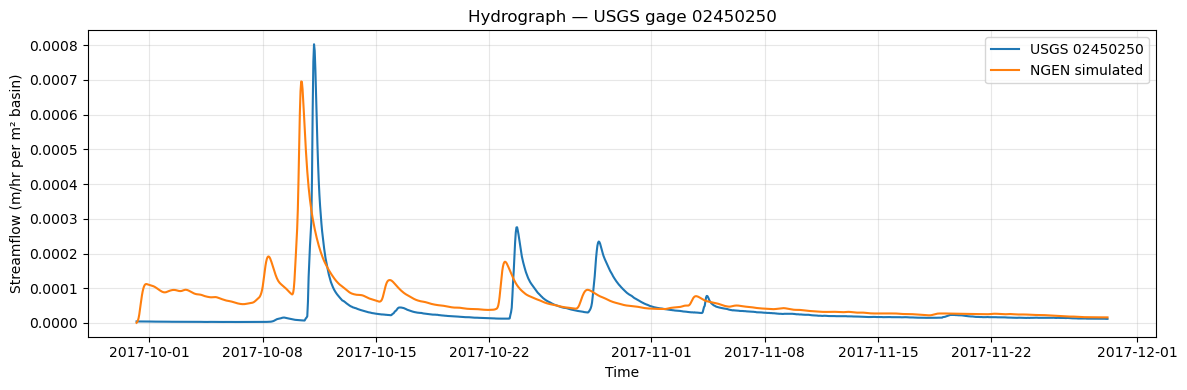

In [7]:
# Hydrograph: USGS observed vs NGEN simulated
plot_hydrograph(hydrograph_df, ngiab_gages_df)

---

### ➡️ Next notebook: [03. TEEHR Evaluation](03.NextGEN_TEEHR_Evaluation.ipynb)